In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv(
    'twitter_training (2).csv',
    header=None
)

# Assign column names
df.columns = ['tweet_id', 'entity', 'sentiment', 'content']

# Display first 5 rows
df.head()

,tweet_id,entity,sentiment,content
0,2401,Borderlands,Positive,im getting on borderlands and i will murder yo...
1,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
2,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
3,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
4,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...


In [23]:
# Check dataset shape
print("Dataset Shape:", df.shape)

# Check dataset information
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

Dataset Shape: (68432, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 68432 entries, 0 to 68431
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   tweet_id   68432 non-null  int64 
 1   entity     68432 non-null  object
 2   sentiment  68432 non-null  object
 3   content    67830 non-null  object
dtypes: int64(1), object(3)
memory usage: 2.1+ MB

Missing Values:
tweet_id       0
entity         0
sentiment      0
content      602
dtype: int64

Duplicate Records: 2487


In [24]:
# Remove missing tweet content
df.dropna(subset=['content'], inplace=True)

# Remove duplicate records
df.drop_duplicates(inplace=True)

# Remove extra spaces
df['content'] = df['content'].str.strip()
df['entity'] = df['entity'].str.strip()
df['sentiment'] = df['sentiment'].str.strip()

# Check cleaned dataset
print("Cleaned Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

Cleaned Dataset Shape: (65656, 4)

Missing Values:
tweet_id     0
entity       0
sentiment    0
content      0
dtype: int64

Duplicate Records: 324


In [25]:
# Remove duplicates again after trimming spaces
df.drop_duplicates(inplace=True)

# Final dataset verification
print("Final Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

Final Dataset Shape: (65332, 4)

Missing Values:
tweet_id     0
entity       0
sentiment    0
content      0
dtype: int64

Duplicate Records: 0


In [26]:
# Count each sentiment category
sentiment_counts = df['sentiment'].value_counts()

print("Sentiment Distribution:")
print(sentiment_counts)

# Calculate percentage
sentiment_percentage = df['sentiment'].value_counts(normalize=True) * 100

print("\nSentiment Percentage:")
print(sentiment_percentage.round(2))

Sentiment Distribution:
sentiment
Negative      20001
Positive      17616
Neutral       15673
Irrelevant    12042
Name: count, dtype: int64

Sentiment Percentage:
sentiment
Negative      30.61
Positive      26.96
Neutral       23.99
Irrelevant    18.43
Name: proportion, dtype: float64


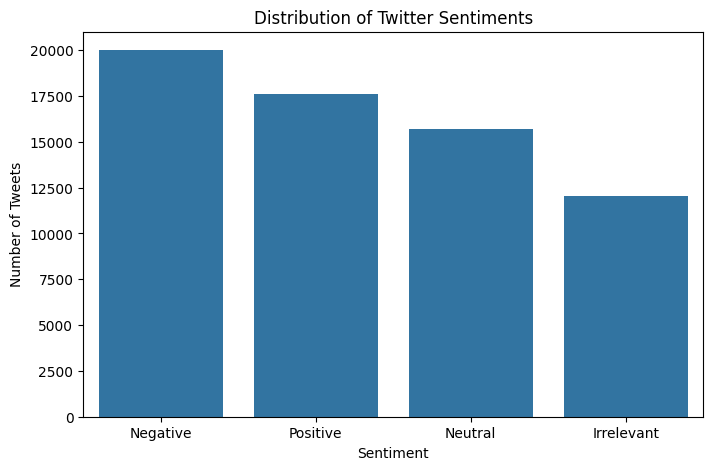

In [27]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='sentiment',
    order=df['sentiment'].value_counts().index
)

plt.title('Distribution of Twitter Sentiments')
plt.xlabel('Sentiment')
plt.ylabel('Number of Tweets')
plt.xticks(rotation=0)
plt.show()

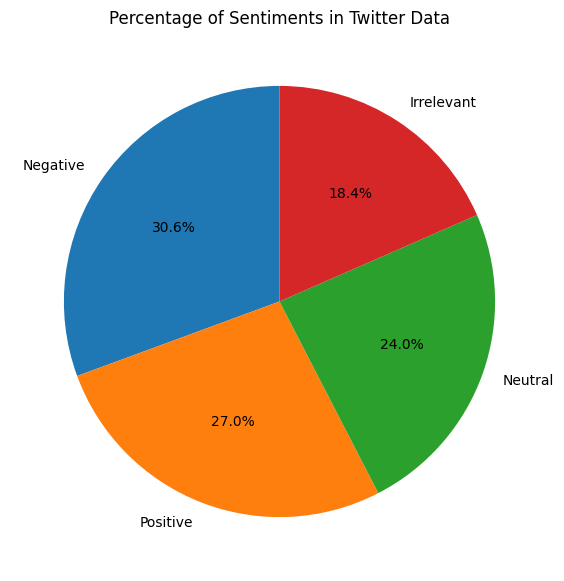

In [28]:
plt.figure(figsize=(7, 7))

plt.pie(
    sentiment_counts,
    labels=sentiment_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Percentage of Sentiments in Twitter Data')
plt.show()

In [29]:
# Group sentiment by entity
entity_sentiment = pd.crosstab(
    df['entity'],
    df['sentiment']
)

# Display first 10 entities
entity_sentiment.head(10)

sentiment,Irrelevant,Negative,Neutral,Positive
entity,,,,
Amazon,185,562,1194,302
ApexLegends,184,568,906,597
AssassinsCreed,254,365,152,1373
Battlefield,906,439,338,556
Borderlands,237,414,579,967
CS-GO,618,334,522,715
CallOfDuty,653,858,366,423
CallOfDutyBlackopsColdWar,540,534,339,809
Cyberpunk2077,121,124,142,277


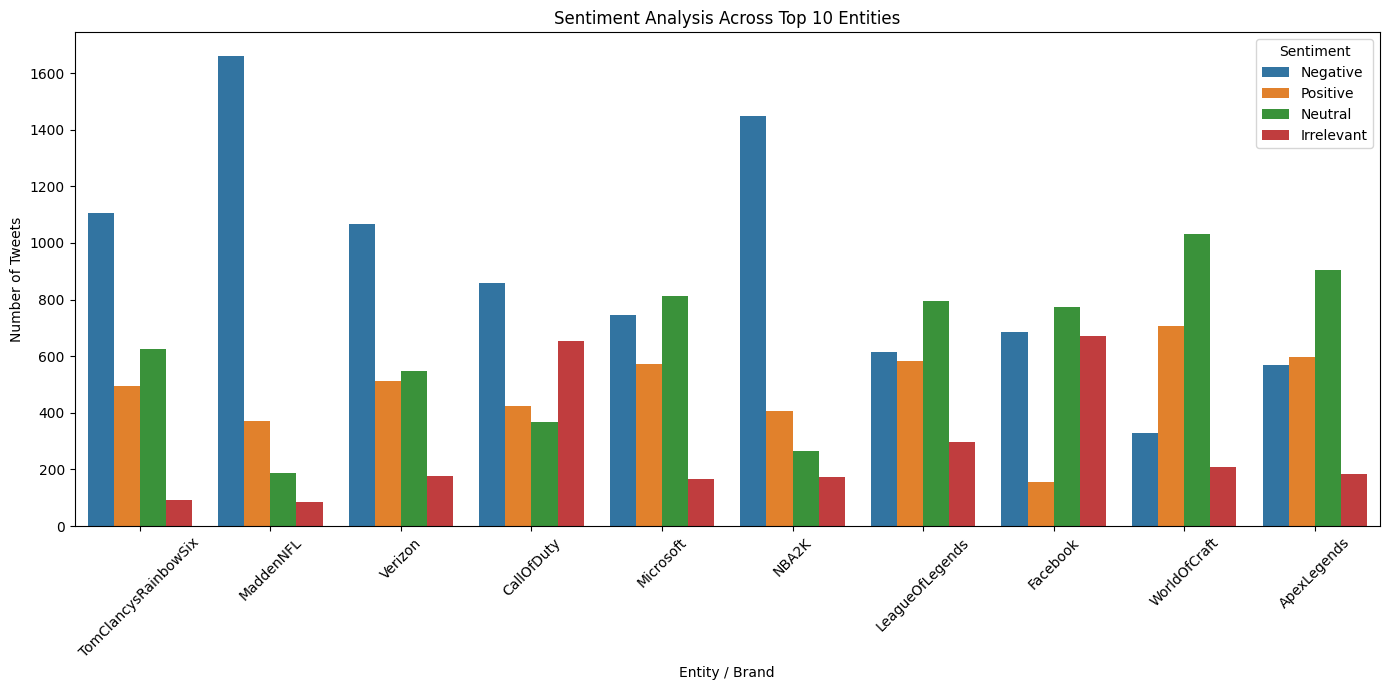

In [30]:
# Select top 10 entities by tweet count
top_entities = df['entity'].value_counts().head(10).index

# Filter data
top_data = df[df['entity'].isin(top_entities)]

# Create sentiment comparison
plt.figure(figsize=(14, 7))

sns.countplot(
    data=top_data,
    x='entity',
    hue='sentiment',
    order=top_entities
)

plt.title('Sentiment Analysis Across Top 10 Entities')
plt.xlabel('Entity / Brand')
plt.ylabel('Number of Tweets')
plt.xticks(rotation=45)
plt.legend(title='Sentiment')
plt.tight_layout()
plt.show()

In [31]:
# Calculate positive and negative tweets
positive_entities = df[df['sentiment'] == 'Positive']['entity'].value_counts()
negative_entities = df[df['sentiment'] == 'Negative']['entity'].value_counts()

print("Top 5 Positive Entities:")
print(positive_entities.head())

print("\nTop 5 Negative Entities:")
print(negative_entities.head())

Top 5 Positive Entities:
entity
AssassinsCreed               1373
Borderlands                   967
PlayStation5(PS5)             886
RedDeadRedemption(RDR)        881
CallOfDutyBlackopsColdWar     809
Name: count, dtype: int64

Top 5 Negative Entities:
entity
MaddenNFL               1661
NBA2K                   1447
FIFA                    1124
TomClancysRainbowSix    1106
Verizon                 1066
Name: count, dtype: int64


In [32]:
import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Convert text to lowercase and remove special characters
df['cleaned_text'] = df['content'].str.lower()

df['cleaned_text'] = df['cleaned_text'].apply(
    lambda text: re.sub(r'[^a-z\s]', '', text)
)

# Remove stopwords
df['cleaned_text'] = df['cleaned_text'].apply(
    lambda text: ' '.join(
        word for word in text.split()
        if word not in ENGLISH_STOP_WORDS
    )
)

df[['content', 'cleaned_text']].head()

,content,cleaned_text
0,im getting on borderlands and i will murder yo...,im getting borderlands murder
1,I am coming to the borders and I will kill you...,coming borders kill
2,im getting on borderlands and i will kill you ...,im getting borderlands kill
3,im coming on borderlands and i will murder you...,im coming borderlands murder
4,im getting on borderlands 2 and i will murder ...,im getting borderlands murder


In [33]:
from collections import Counter

# Combine all cleaned tweets
all_words = ' '.join(df['cleaned_text'].dropna())

# Count word frequency
word_counts = Counter(all_words.split())

# Display top 20 words
most_common_words = word_counts.most_common(20)

print("Top 20 Most Common Words:")
print(most_common_words)

Top 20 Most Common Words:
[('game', 7153), ('just', 5987), ('like', 4446), ('im', 4411), ('good', 3142), ('play', 3105), ('really', 2895), ('love', 2889), ('johnson', 2801), ('new', 2696), ('people', 2633), ('time', 2611), ('dont', 2474), ('shit', 2467), ('best', 2297), ('got', 2120), ('games', 2076), ('playing', 1999), ('xbox', 1976), ('facebook', 1968)]


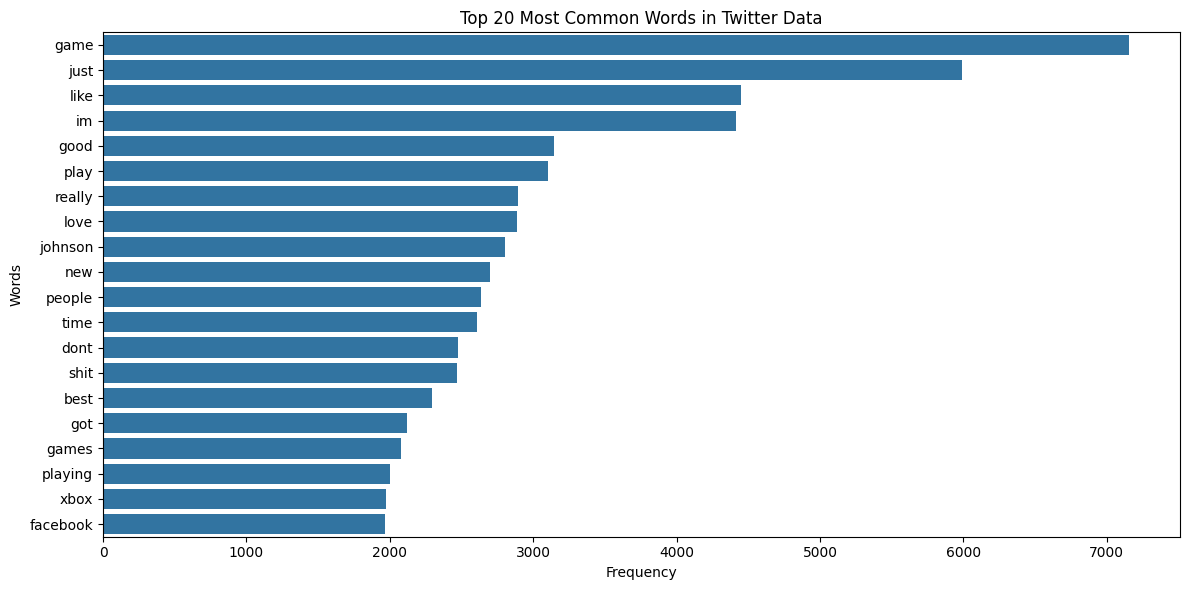

In [34]:
words_df = pd.DataFrame(
    most_common_words,
    columns=['Word', 'Frequency']
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=words_df,
    x='Frequency',
    y='Word'
)

plt.title('Top 20 Most Common Words in Twitter Data')
plt.xlabel('Frequency')
plt.ylabel('Words')
plt.tight_layout()
plt.show()

In [35]:
!pip install wordcloud

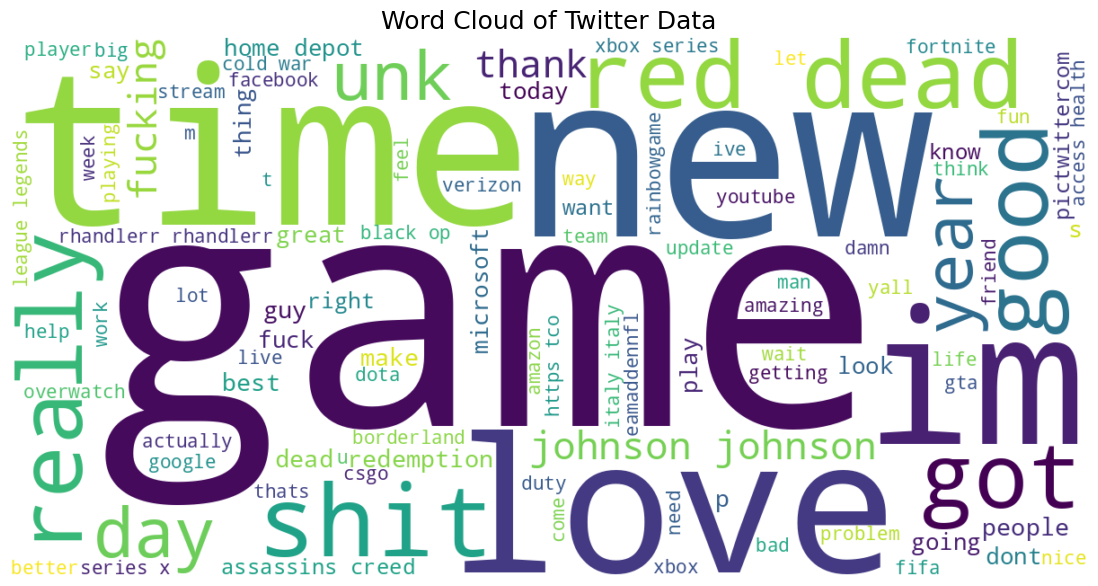

In [36]:
from wordcloud import WordCloud

# Combine cleaned tweets
all_text = ' '.join(df['cleaned_text'].dropna())

# Generate word cloud
wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color='white',
    colormap='viridis',
    max_words=100
).generate(all_text)

# Display word cloud
plt.figure(figsize=(15, 7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud of Twitter Data', fontsize=18)
plt.show()

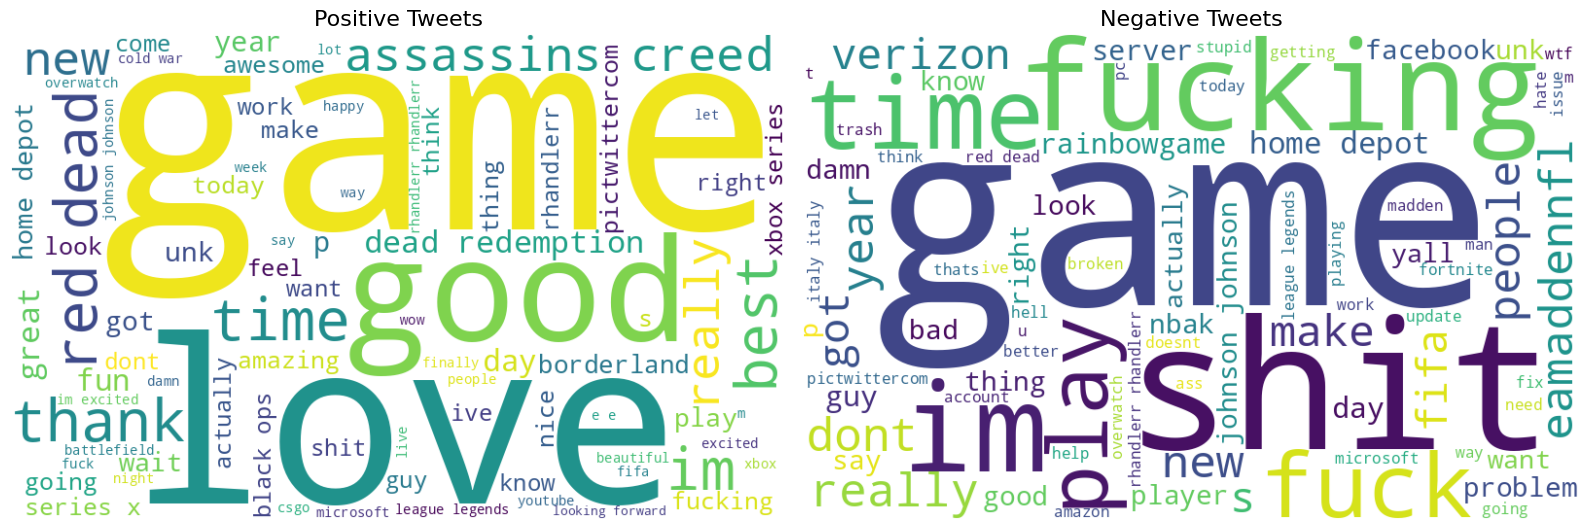

In [37]:
positive_text = ' '.join(
    df[df['sentiment'] == 'Positive']['cleaned_text'].dropna()
)

negative_text = ' '.join(
    df[df['sentiment'] == 'Negative']['cleaned_text'].dropna()
)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, text, title in zip(
    axes,
    [positive_text, negative_text],
    ['Positive Tweets', 'Negative Tweets']
):
    wc = WordCloud(
        width=800,
        height=500,
        background_color='white',
        max_words=80
    ).generate(text)

    ax.imshow(wc, interpolation='bilinear')
    ax.set_title(title, fontsize=16)
    ax.axis('off')

plt.tight_layout()
plt.show()

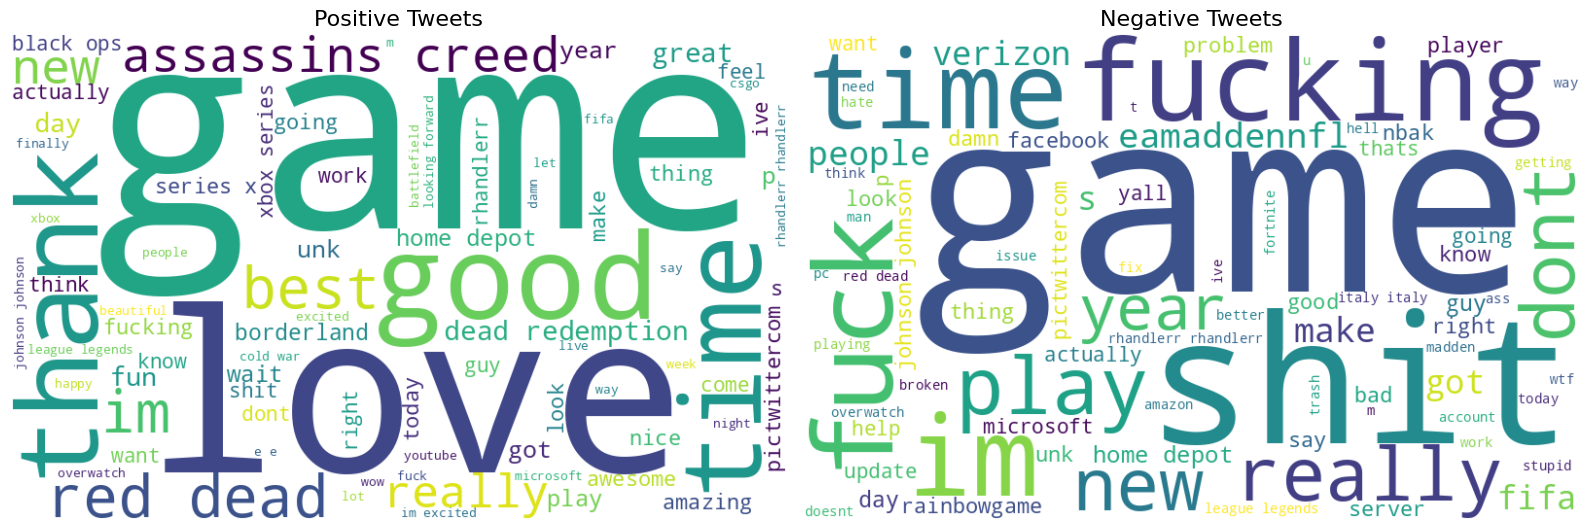

In [38]:
positive_text = ' '.join(
    df[df['sentiment'] == 'Positive']['cleaned_text'].dropna()
)

negative_text = ' '.join(
    df[df['sentiment'] == 'Negative']['cleaned_text'].dropna()
)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, text, title in zip(
    axes,
    [positive_text, negative_text],
    ['Positive Tweets', 'Negative Tweets']
):
    wc = WordCloud(
        width=800,
        height=500,
        background_color='white',
        max_words=80
    ).generate(text)

    ax.imshow(wc, interpolation='bilinear')
    ax.set_title(title, fontsize=16)
    ax.axis('off')

plt.tight_layout()
plt.show()

In [39]:
# Calculate sentiment counts
sentiment_summary = df['sentiment'].value_counts().reset_index()

sentiment_summary.columns = ['Sentiment', 'Total Tweets']

# Calculate percentage
sentiment_summary['Percentage'] = (
    sentiment_summary['Total Tweets'] /
    sentiment_summary['Total Tweets'].sum()
) * 100

print("Overall Sentiment Analysis")
display(sentiment_summary.round(2))

# Identify the most common sentiment
print("\nMost Common Sentiment:",
      sentiment_summary.iloc[0]['Sentiment'])

Overall Sentiment Analysis


,Sentiment,Total Tweets,Percentage
0,Negative,20001,30.61
1,Positive,17616,26.96
2,Neutral,15673,23.99
3,Irrelevant,12042,18.43



Most Common Sentiment: Negative


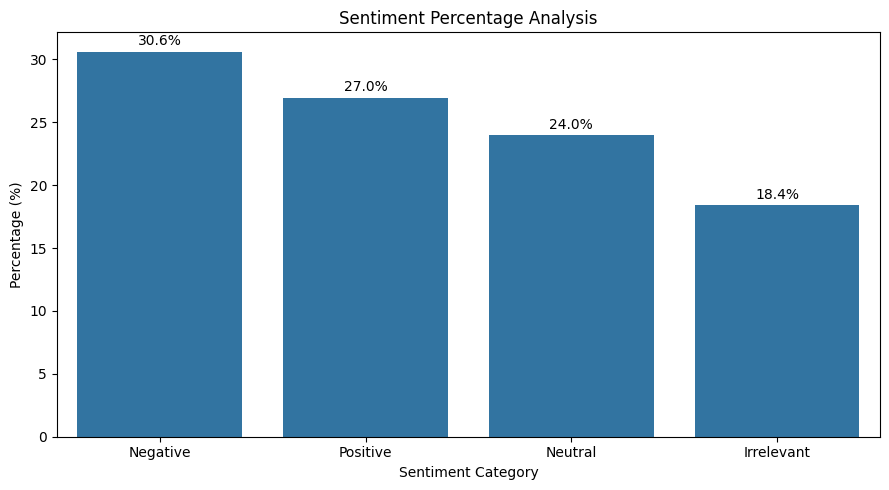

In [40]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=sentiment_summary,
    x='Sentiment',
    y='Percentage'
)

plt.title('Sentiment Percentage Analysis')
plt.xlabel('Sentiment Category')
plt.ylabel('Percentage (%)')

for i, value in enumerate(sentiment_summary['Percentage']):
    plt.text(i, value + 0.5, f'{value:.1f}%', ha='center')

plt.tight_layout()
plt.show()

In [41]:
print("========== KEY FINDINGS ==========")

print("Total Tweets:", len(df))

print("\nSentiment Distribution:")
print(df['sentiment'].value_counts())

print("\nTop 5 Most Discussed Topics:")
print(df['entity'].value_counts().head(5))

print("\nMost Common Sentiment:")
print(df['sentiment'].value_counts().idxmax())

print("\nTotal Unique Entities:", df['entity'].nunique())

========== KEY FINDINGS ==========
Total Tweets: 65332

Sentiment Distribution:
sentiment
Negative      20001
Positive      17616
Neutral       15673
Irrelevant    12042
Name: count, dtype: int64

Top 5 Most Discussed Topics:
entity
TomClancysRainbowSix    2316
MaddenNFL               2308
Verizon                 2304
CallOfDuty              2300
Microsoft               2297
Name: count, dtype: int64

Most Common Sentiment:
Negative

Total Unique Entities: 30


## Conclusion – Twitter Sentiment Analysis

The Twitter Sentiment Analysis project was performed to understand public opinions and attitudes towards different topics and brands using social media data.

The dataset was analyzed using Python libraries such as Pandas, NumPy, Matplotlib, and Seaborn.

Data cleaning and preprocessing techniques were applied to handle missing values, duplicate records, and unnecessary spaces.

Exploratory Data Analysis (EDA) was performed to understand sentiment distribution, identify popular entities, and analyze frequently used words.

Different visualizations, including bar charts, pie charts, and word clouds, were created to present the findings clearly.

The analysis helped identify positive, negative, neutral, and irrelevant sentiments in the dataset.

Overall, this project provided practical experience in data cleaning, text preprocessing, exploratory data analysis, and data visualization. It demonstrates how social media data can be analyzed to understand public opinion.